# Estimate an equivalent layer by using the correct magnetization direction

### Things we have to import

In [1]:
import numpy as np

In [2]:
import matplotlib.pyplot as plt

In [3]:
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

In [4]:
import time

In [5]:
import pickle

In [6]:
from scipy.integrate import quad
from scipy.optimize import minimize

In [7]:
from gravmag import data_structures, utils, aux_vedo, transforms, inverse_distance, convolve, filters, constants, eqlayer
from gravmag.models import rectangular_prism as rp

In [8]:
# Function for evaluating the general error bound
def integrand(k, Dz, q):
    return np.exp(-2*Dz*k)*(k**(2*q-1))*((2*Dz)**(2*q))

In [9]:
import vedo

In [10]:
# set the backend for vedo
vedo.settings.default_backend= 'vtk'
#vedo.settings.default_backend= '2d'

### Load data

In [11]:
boundary_points = pickle.load(open('model_boundary_points.pickle', 'rb'))

In [12]:
# append the first point at the end to plot a closed curve
boundary_points = np.vstack([boundary_points, boundary_points[0]])

In [13]:
model = pickle.load(open('model/model.pickle', 'rb'))

In [14]:
model_area = pickle.load(open('model/model_area.pickle', 'rb'))
model_shape = pickle.load(open('model/model_shape.pickle', 'rb'))

In [15]:
mag_intensity = pickle.load(open('model/model_mag_intensity.pickle', 'rb'))
mag_inc = pickle.load(open('model/model_mag_inc.pickle', 'rb'))
mag_dec = pickle.load(open('model/model_mag_dec.pickle', 'rb'))

In [16]:
mag_inc[0], mag_dec[0]

(-10.2, -19.8)

In [17]:
main_field = pickle.load(open('model/main_field.pickle', 'rb'))

In [18]:
V = pickle.load(open('model/magnetic_potential.pickle', 'rb'))
bx = pickle.load(open('model/magnetic_field_component_bx.pickle', 'rb'))
by = pickle.load(open('model/magnetic_field_component_by.pickle', 'rb'))
bz = pickle.load(open('model/magnetic_field_component_bz.pickle', 'rb'))
rtp = pickle.load(open('model/rtp.pickle', 'rb'))
pseudo_grav = pickle.load(open('model/pseudo_grav.pickle', 'rb'))
pseudo_grav_layer = pickle.load(open('model/pseudo_grav_layer.pickle', 'rb'))

In [19]:
simulated_fields = dict()
simulated_fields['bx'] = bx
simulated_fields['by'] = by
simulated_fields['bz'] = bz
simulated_fields['rtp'] = rtp

In [20]:
coordinates_grid = pickle.load(open('model/coordinates_grid.pickle', 'rb'))

In [21]:
print('Regular grid of coordinates on the horizontal plane {} m'.format(coordinates_grid['z']))

Regular grid of coordinates on the horizontal plane -150 m


### Get preliminary information from loaded data

In [22]:
# Grid spacing
dx, dy = data_structures.grid_xy_spacing(coordinates_grid['area'], coordinates_grid['shape'])

In [23]:
X, Y = data_structures.grid_xy_to_full_matrices_view(
    x = coordinates_grid['x'],
    y = coordinates_grid['y'],
    shape = coordinates_grid['shape']
)

In [24]:
# Cartesian components of the main field
Fx_hat, Fy_hat, Fz_hat = utils.unit_vector(inc=main_field['inc'], dec=main_field['dec'])

In [25]:
# compute the amplitude of the anomalous magnetic (crustal) field
b_amp = np.sqrt(bx**2 + by**2 + bz**2)

# compute the approximated total-field anomaly (Blakely, 1996, p. 179)
approx_tfa = Fx_hat*bx + Fy_hat*by + Fz_hat*bz

In [26]:
simulated_fields['amplitude'] = b_amp
simulated_fields['atfa'] = approx_tfa

In [27]:
# Cartesian components of the main field
F_hat = utils.unit_vector(inc=main_field['inc'], dec=main_field['dec'])

In [28]:
# Cartesian components of the dipoles forming the equivalent layers
h_hat = utils.unit_vector(inc=mag_inc[0], dec=mag_dec[0])

In [29]:
# volume of the prisms forming the model
prisms_volume = utils.prisms_volume(model)

# total magnetic moment
total_moment = np.sum(mag_intensity*prisms_volume)

print('Total magnetic moment of the model: {:.3e} Am²'.format(total_moment))

Total magnetic moment of the model: 5.106e+10 Am²


### Compute the generic dipole layer from the pseudogravity anomaly on the layer

In [30]:
# set a layer that crosses the sources
z_layer = 200

In [31]:
print('The distance from coordinates grid to layer is {} m'.format(z_layer-coordinates_grid['z']))

The distance from coordinates grid to layer is 350 m


In [32]:
# compute 2D Fourier transform of pseudogravity anomaly by apllying padding
FT_pseudo_grav_layer = transforms.DFT(
    data = data_structures.grid_xy_full_flatten_to_matrix(
        data = pseudo_grav_layer, ordering='xy', shape=coordinates_grid['shape']
    ), 
    pad_mode='linear_ramp'
)

In [33]:
# compute wavenumbers
wavenumbers = data_structures.grid_wavenumbers(grid = coordinates_grid, pad = True)

In [34]:
# directional filter using the true magnetization direction of the sources
true_mag_direction = filters.direction(wavenumbers=wavenumbers, inc=mag_inc[0], dec=mag_dec[0])

# arbitrary direction for the dipole layer
inc_assumed = 40
dec_assumed = 5
assumed_hat = utils.unit_vector(inc=inc_assumed, dec=dec_assumed)
assumed_mag_direction = filters.direction(
    wavenumbers=wavenumbers, inc=inc_assumed, dec=dec_assumed
)
assumed_mag_direction[0,0] = 1.0 # avoid division by zero

# directional filter defined as the ratio of true and assumed directions
directional_filter = true_mag_direction / assumed_mag_direction

In [35]:
# Compute the dipole layer by convolving the pseudogravity anomaly with
# the directional filter on the layer
FT_dipole_layer = FT_pseudo_grav_layer * directional_filter

In [36]:
# compute the diṕole layer in the space domain
dipole_layer = transforms.IDFT(FT_data=FT_dipole_layer, unpad=True)

In [37]:
# the dipole layer is arranged as a matrix
dipole_layer.shape

(400, 330)

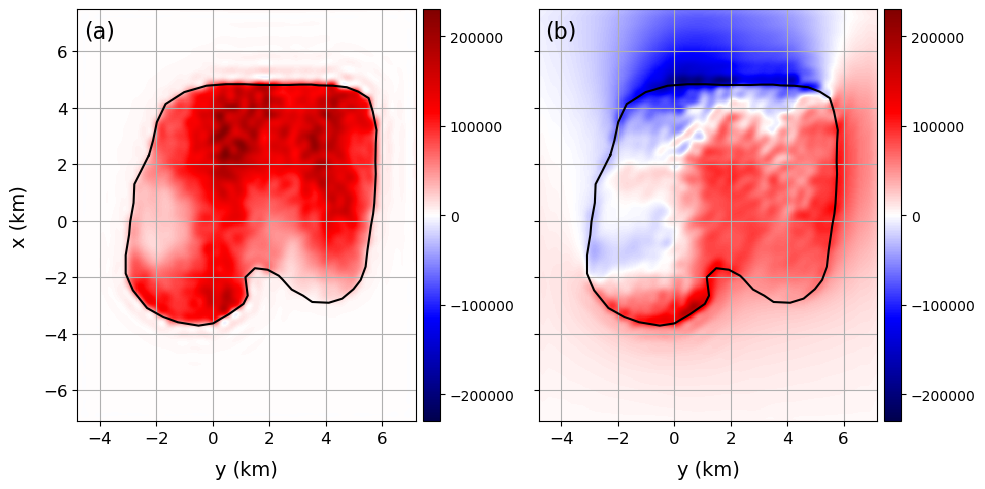

In [38]:
fig, axs = plt.subplots(
    ncols=2, nrows=1, 
    sharex=False, sharey=True,
    figsize=(10, 5), 
)

bounds = np.max(np.abs(pseudo_grav_layer))

axs[0].axis('scaled')
image = axs[0].pcolormesh(
    Y*0.001, X*0.001, 
    data_structures.grid_xy_full_flatten_to_matrix(
        data=pseudo_grav_layer,
        ordering='xy',
        shape=coordinates_grid['shape']
    ),
    cmap='seismic', vmin=-bounds, vmax=bounds
)
axs[0].set_ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
axs[0].set_xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
axs[0].tick_params(axis='both', labelsize=12)
ax_divider = make_axes_locatable(axs[0])
cax = ax_divider.append_axes("right", size="5%", pad="2%")
cb = fig.colorbar(image, cax=cax)
axs[0].grid()
axs[0].set_ylabel('x (km)', fontsize=14, labelpad=10)
axs[0].set_xlabel('y (km)', fontsize=14, labelpad=10)
axs[0].annotate('(a)', xy=(0.02, 0.93), xycoords='axes fraction', fontsize=16)
axs[0].plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')

bounds = np.max(np.abs(pseudo_grav_layer))

axs[1].axis('scaled')
image = axs[1].pcolormesh(
    Y*0.001, X*0.001, 
    dipole_layer,
    cmap='seismic', vmin=-bounds, vmax=bounds
)
axs[1].set_ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
axs[1].set_xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
axs[1].tick_params(axis='both', labelsize=12)
ax_divider = make_axes_locatable(axs[1])
cax = ax_divider.append_axes("right", size="5%", pad="2%")
cb = fig.colorbar(image, cax=cax)
axs[1].grid()
axs[1].set_xlabel('y (km)', fontsize=14, labelpad=10)
axs[1].annotate('(b)', xy=(0.02, 0.93), xycoords='axes fraction', fontsize=16)
axs[1].plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')

# set vertical and horizontal spaces between subplots
#fig.subplots_adjust(wspace=0.20, hspace=0.05)

plt.tight_layout()

plt.savefig('discrete_layers.png', dpi=300)

plt.show()

### Compute the data fit

In [39]:
# compute 2D Fourier transform of pseudogravity anomaly by apllying padding
FT_dipole_layer = transforms.DFT(
    data = dipole_layer, 
    pad_mode='linear_ramp'
)

In [40]:
# compute wavenumbers
wavenumbers = data_structures.grid_wavenumbers(grid = coordinates_grid, pad = True)

In [41]:
# compute the SEDM
R2 = inverse_distance.sedm_BTTB(
    data_grid = coordinates_grid, 
    delta_z = z_layer - coordinates_grid['z'],
    ordering = 'xy'
)

In [42]:
# compute the tensor components (second derivatives) of the inverse distance function
Tensor = inverse_distance.grad_tensor_BTTB(
    data_grid = coordinates_grid,
    delta_z = z_layer - coordinates_grid['z'],
    SEDM = R2,
    ordering = 'xy',
    components=['xx', 'xy', 'xz', 'yy', 'yz', 'zz']
)

In [43]:
# compute the eigenvalues matrices associated to second derivatives of inverse distance function
L_Tensor = dict()
for component in ['xx', 'xy', 'xz', 'yy', 'yz', 'zz']:
    L_Tensor[component] = convolve.eigenvalues_BCCB(BTTB_metadata=Tensor[component])

In [44]:
# directional factor to compute the approximated total-field anomaly
a = utils.directional_factors(t=assumed_hat, u=F_hat)

In [45]:
# list for storing the predicted magnetic field components
predicted_fields = dict()

In [46]:
# change CM * T2microT to CM * T2nanoT
print(
    'CM * T2microT = {:.0e} | CM * T2nanoT = {:.0e}'.format(
        constants.CM * constants.T2microT,
        constants.CM * constants.T2nanoT
    )
)

scale_factor = 1e3 # ( constants.CM * constants.T2nanoT ) / ( constants.CM * constants.T2microT ) 

CM * T2microT = 1e-01 | CM * T2nanoT = 1e+02


In [47]:
# magnetic induction field component x
result = np.zeros_like(bx)

for h_component, component in zip(assumed_hat, ['xx', 'xy', 'xz']):
    result[:] += h_component*convolve.product_BCCB_vector(
        eigenvalues = L_Tensor[component],
        ordering = 'row',
        v = data_structures.grid_xy_full_matrix_to_flatten(
            grid=dipole_layer, ordering='xy'
        )
    )

predicted_fields['bx'] = scale_factor*result

# magnetic induction field component y
result = np.zeros_like(by)

for h_component, component in zip(assumed_hat, ['xy', 'yy', 'yz']):
    result[:] += h_component*convolve.product_BCCB_vector(
        eigenvalues = L_Tensor[component],
        ordering = 'row',
        v = data_structures.grid_xy_full_matrix_to_flatten(
            grid=dipole_layer, ordering='xy'
        )
    )

predicted_fields['by'] = scale_factor*result

# magnetic induction field component z
result = np.zeros_like(bz)

for h_component, component in zip(assumed_hat, ['xz', 'yz', 'zz']):
    result[:] += h_component*convolve.product_BCCB_vector(
        eigenvalues = L_Tensor[component],
        ordering = 'row',
        v = data_structures.grid_xy_full_matrix_to_flatten(
            grid=dipole_layer, ordering='xy'
        )
    )

predicted_fields['bz'] = scale_factor*result

In [48]:
# amplitude of anomalous B field
predicted_fields['amplitude'] = np.sqrt(
    predicted_fields['bx']**2 + 
    predicted_fields['by']**2 + 
    predicted_fields['bz']**2
)

In [49]:
# reduction to the pole
result = convolve.product_BCCB_vector(
    eigenvalues = L_Tensor['zz'],
    ordering = 'row',
    v = data_structures.grid_xy_full_matrix_to_flatten(
        grid=dipole_layer, ordering='xy'
    )
)

predicted_fields['rtp'] = scale_factor*result

In [50]:
# approximated total-field anomaly
result = np.zeros_like(bz)

for component in ['xx', 'xy', 'xz', 'yy', 'yz']:
    result[:] += convolve.product_BCCB_vector(
        eigenvalues = a[component]*L_Tensor[component],
        ordering = 'row',
        v = data_structures.grid_xy_full_matrix_to_flatten(
            grid=dipole_layer, ordering='xy'
        )
    )

predicted_fields['atfa'] = scale_factor*result

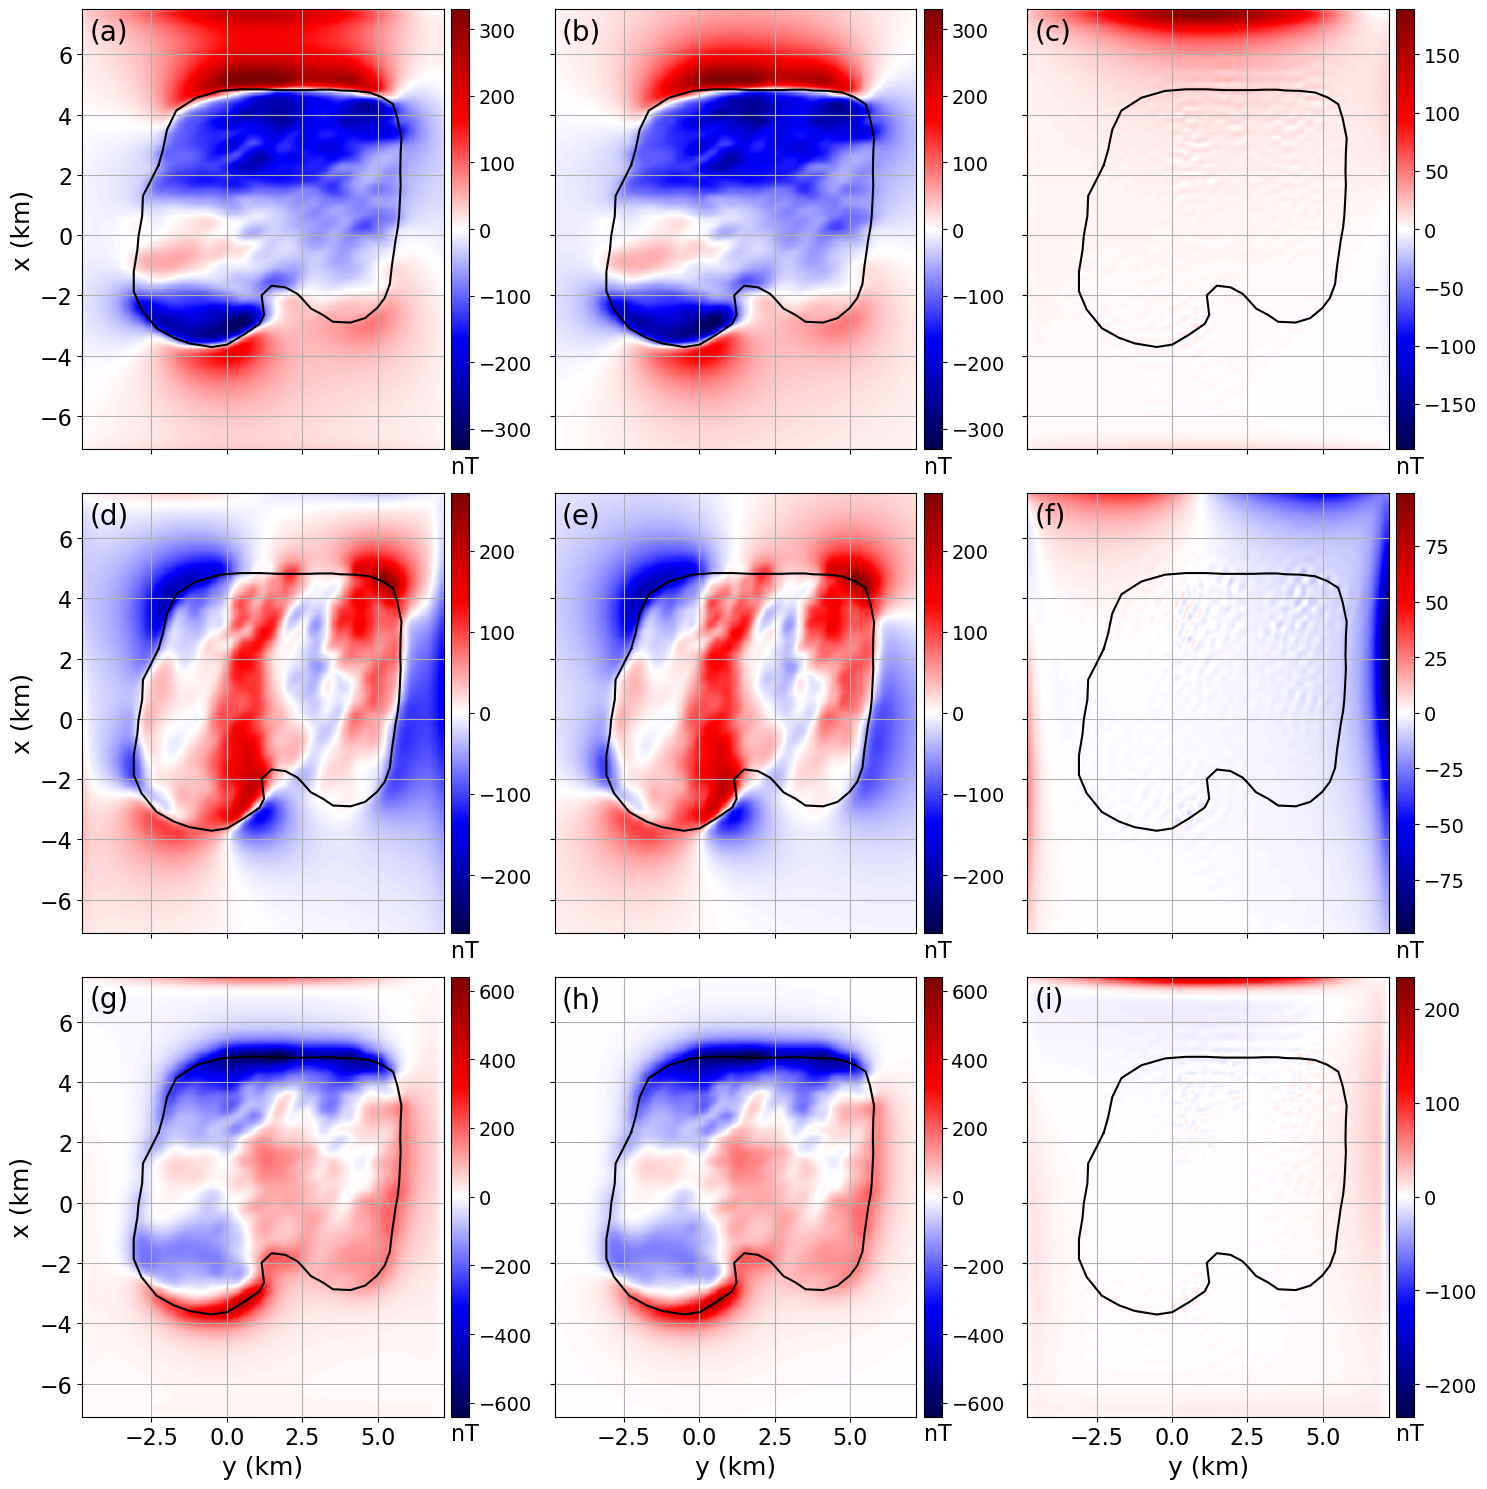

In [51]:
# plot figure
fig = plt.figure(
    layout= 'tight', 
    figsize=(15,15)
)
mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             def
             ghi
             ''',
    sharex=True, sharey=True
)

labels = [['(a)', '(b)', '(c)'], ['(d)', '(e)', '(f)'], ['(g)', '(h)', '(i)']]

mosaic_elements = [['a', 'b', 'c'], ['d', 'e', 'f'], ['g', 'h', 'i']]

for (mosaic_row, field, labels_row) in zip(
    mosaic_elements, 
    ['bx', 'by', 'bz'],
    labels
):
    data_list = [
        predicted_fields[field], 
        simulated_fields[field],
        predicted_fields[field] - simulated_fields[field]
    ]
    bounds_list = 2*[np.max(np.abs(simulated_fields[field]))] + [np.max(np.abs(data_list[2]))]
    titles = ['predicted '+field, 'simulated '+field, 'difference '+field]
    
    for mosaic_element, data, bound, label, title in zip(mosaic_row, data_list, bounds_list, labels_row, titles):
    
        ax = mosaic[mosaic_element]
        ax.axis('scaled')
        im = ax.pcolormesh(
            Y*0.001, X*0.001, 
            data_structures.grid_xy_full_flatten_to_matrix(
                data=data,
                ordering='xy',
                shape=coordinates_grid['shape']
            ),
            cmap='seismic', vmin=-bound, vmax=bound
        )
        ax_divider = make_axes_locatable(ax)
        cax = ax_divider.append_axes("right", size="5%", pad="2%")
        cb = fig.colorbar(im, cax=cax)
        cb.ax.tick_params(labelsize=14)
        cb.ax.set_xlabel('nT', fontsize=16, loc='left')
        ax.plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')
        ax.set_ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
        ax.set_xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
        ax.tick_params(axis='x', labelsize=16)
        ax.tick_params(axis='y', labelsize=16)
        ax.grid()
        ax.annotate(label, xy=(0.02, 0.93), xycoords='axes fraction', fontsize=20)
        #ax.annotate(title, xy=(0.02, 0.03), xycoords='axes fraction', fontsize=14)

# set vertical and horizontal spaces between subplots
#fig.subplots_adjust(wspace=0.20, hspace=0.30)
    
for element in ['a','d','g']:
    mosaic[element].set_ylabel('x (km)', fontsize=18)
for element in ['g','h', 'i']:
    mosaic[element].set_xlabel('y (km)', fontsize=18)

plt.savefig('generic_bx_by_bz.png', dpi=300)

plt.show()

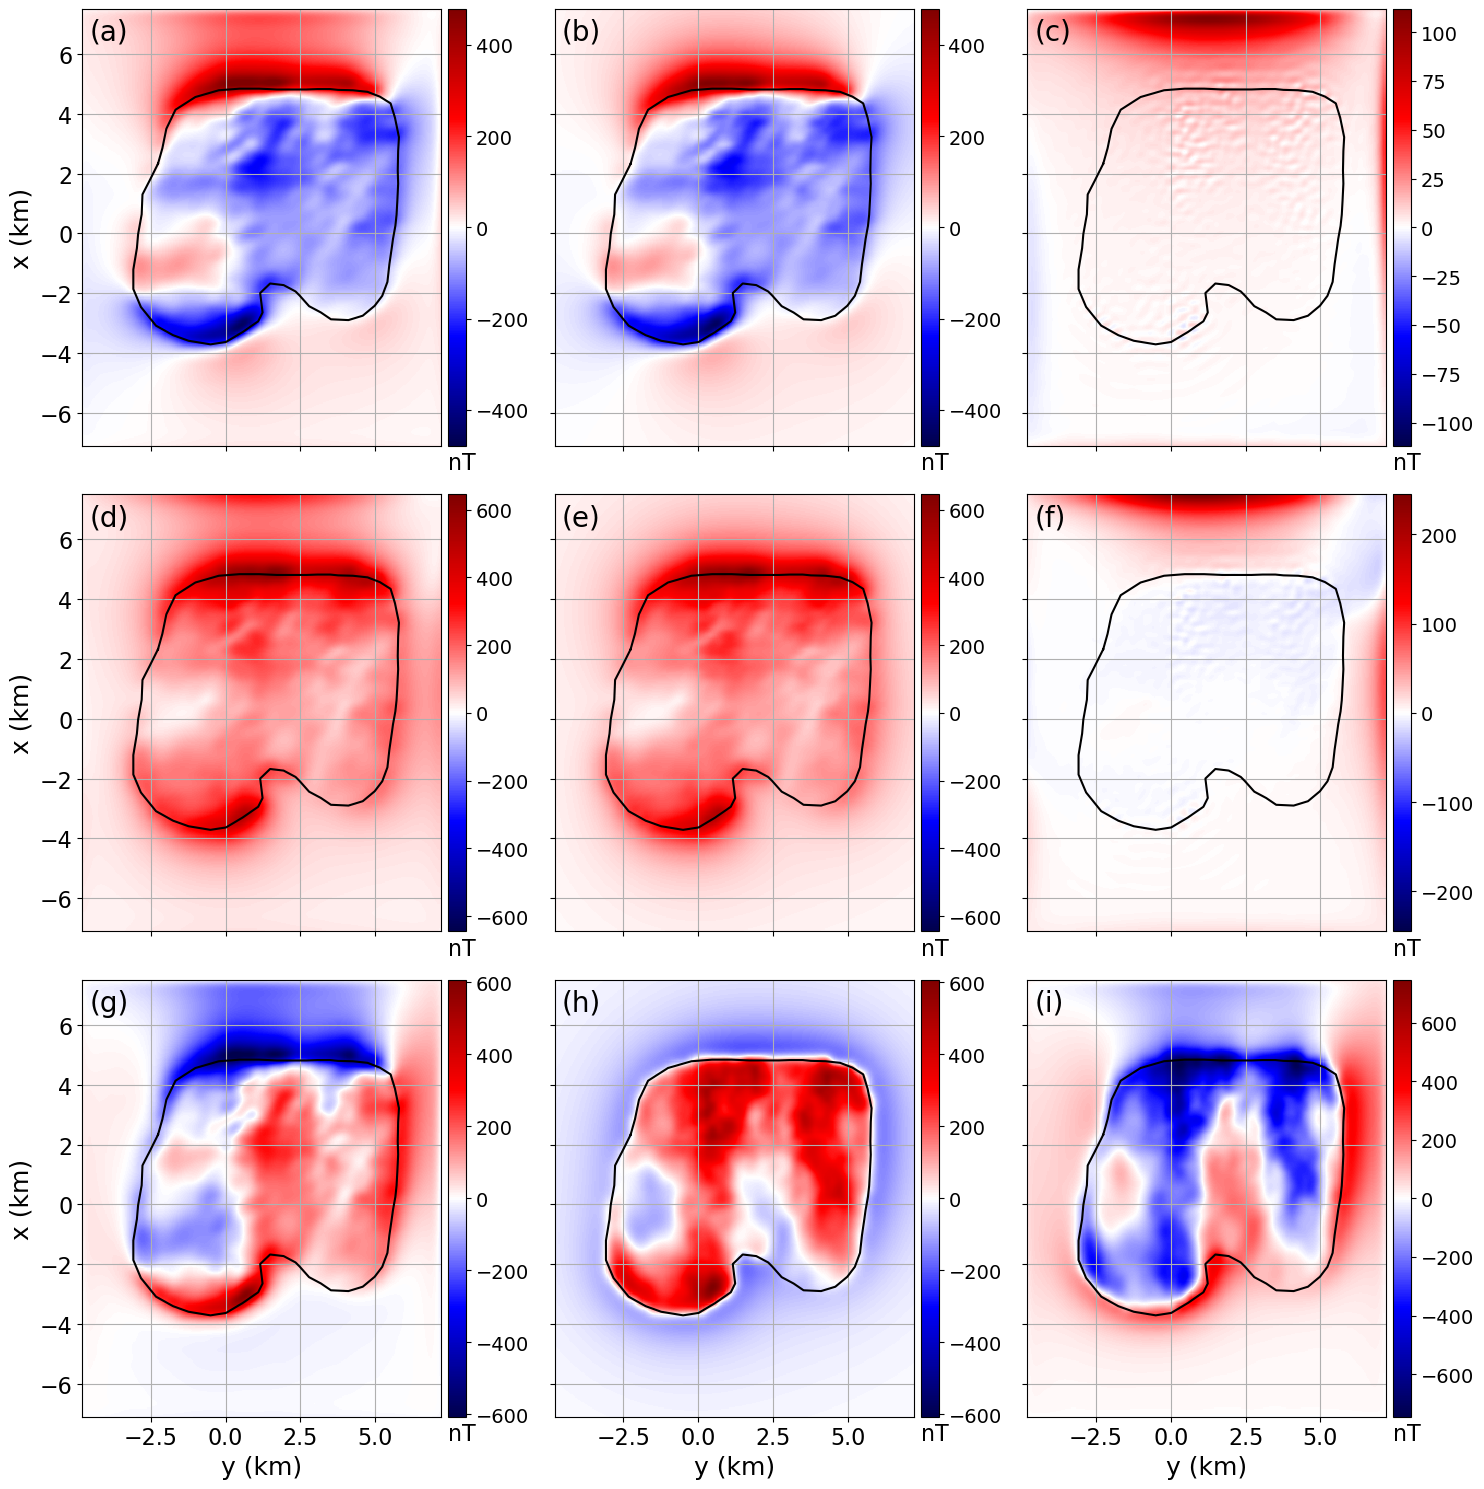

In [52]:
# plot figure
fig = plt.figure(
    layout= 'tight', 
    figsize=(15,15)
)
mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             def
             ghi
             ''',
    sharex=True, sharey=True
)

labels = [['(a)', '(b)', '(c)'], ['(d)', '(e)', '(f)'], ['(g)', '(h)', '(i)']]

mosaic_elements = [['a', 'b', 'c'], ['d', 'e', 'f'], ['g', 'h', 'i']]

for (mosaic_row, field, labels_row) in zip(
    mosaic_elements, 
    ['atfa', 'amplitude', 'rtp'],
    labels
):
    data_list = [
        predicted_fields[field], 
        simulated_fields[field],
        predicted_fields[field] - simulated_fields[field]
    ]
    bounds_list = 2*[np.max(np.abs(simulated_fields[field]))] + [np.max(np.abs(data_list[2]))]
    titles = ['predicted '+field, 'simulated '+field, 'difference '+field]
    
    for mosaic_element, data, bound, label, title in zip(mosaic_row, data_list, bounds_list, labels_row, titles):
    
        ax = mosaic[mosaic_element]
        ax.axis('scaled')
        im = ax.pcolormesh(
            Y*0.001, X*0.001, 
            data_structures.grid_xy_full_flatten_to_matrix(
                data=data,
                ordering='xy',
                shape=coordinates_grid['shape']
            ),
            cmap='seismic', vmin=-bound, vmax=bound
        )
        ax_divider = make_axes_locatable(ax)
        cax = ax_divider.append_axes("right", size="5%", pad="2%")
        cb = fig.colorbar(im, cax=cax)
        cb.ax.tick_params(labelsize=14)
        cb.ax.set_xlabel('nT', fontsize=16, loc='left')
        ax.plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')
        ax.set_ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
        ax.set_xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
        ax.tick_params(axis='x', labelsize=16)
        ax.tick_params(axis='y', labelsize=16)
        ax.grid()
        ax.annotate(label, xy=(0.02, 0.93), xycoords='axes fraction', fontsize=20)
        #ax.annotate(title, xy=(0.02, 0.03), xycoords='axes fraction', fontsize=14)

# set vertical and horizontal spaces between subplots
#fig.subplots_adjust(wspace=0.20, hspace=0.30)
    
for element in ['a','d','g']:
    mosaic[element].set_ylabel('x (km)', fontsize=18)
for element in ['g','h', 'i']:
    mosaic[element].set_xlabel('y (km)', fontsize=18)  

plt.savefig('generic_atfa_b_rtp.png', dpi=300)

plt.show()

### Fix the computed RTP

In [53]:
# compute 2D Fourier transform of RTP anomaly by applying padding
FT_predicted_rtp = transforms.DFT(
    data = data_structures.grid_xy_full_flatten_to_matrix(
        data = predicted_fields['rtp'], ordering='xy', shape=coordinates_grid['shape']
    ), 
    pad_mode='linear_ramp'
)

In [54]:
# new directional filter defined as the ratio of true and assumed directions
assumed_mag_direction[0,0] = 0.0
true_mag_direction[0,0] = 1.0
directional_filter = assumed_mag_direction / true_mag_direction

In [55]:
# Compute the dipole layer by convolving the rtp anomaly with
# the new directional filter on the layer
FT_predicted_rtp *= directional_filter

In [56]:
# compute the diṕole layer in the space domain
predicted_fields['rtp'] = transforms.IDFT(FT_data=FT_predicted_rtp, unpad=True)

In [57]:
predicted_fields['rtp'] = data_structures.grid_xy_full_matrix_to_flatten(
    grid=predicted_fields['rtp'],
    ordering='xy'
)

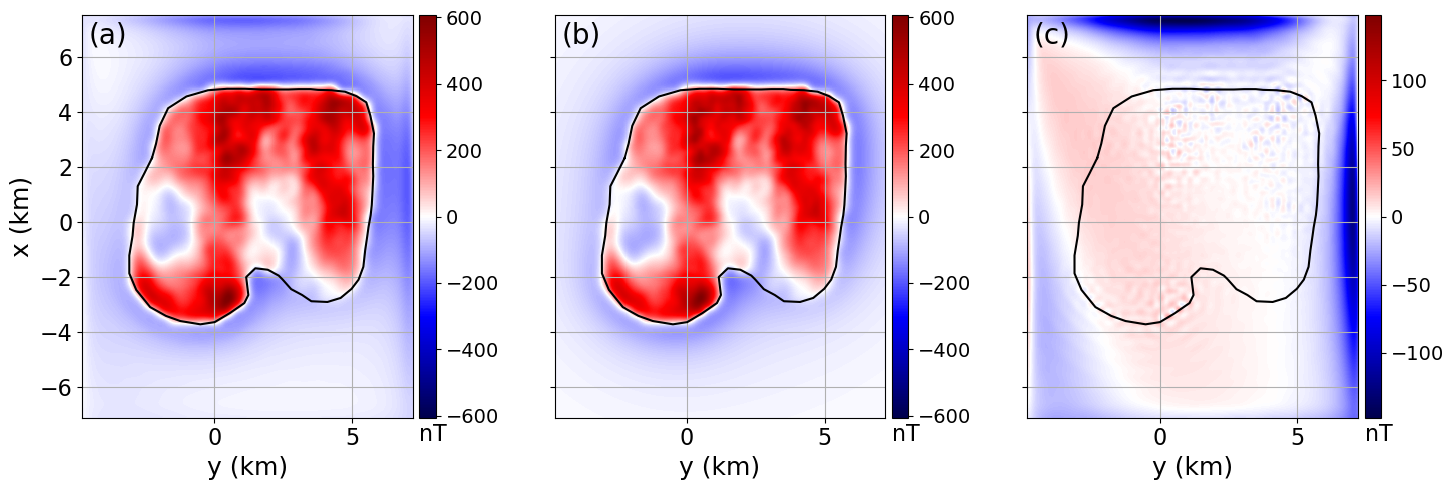

In [61]:
# plot figure
fig = plt.figure(
    layout= 'tight', 
    figsize=(15,5)
)
mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             ''',
    sharex=True, sharey=True
)

labels = [['(a)', '(b)', '(c)']]

mosaic_elements = [['a', 'b', 'c']]

field = 'rtp'

for (mosaic_row, labels_row) in zip(
    mosaic_elements, 
    labels
):
    data_list = [
        predicted_fields[field], 
        simulated_fields[field],
        predicted_fields[field] - simulated_fields[field]
    ]
    bounds_list = 2*[np.max(np.abs(simulated_fields[field]))] + [np.max(np.abs(data_list[2]))]
    titles = ['predicted '+field, 'simulated '+field, 'difference '+field]
    
    for mosaic_element, data, bound, label, title in zip(mosaic_row, data_list, bounds_list, labels_row, titles):
    
        ax = mosaic[mosaic_element]
        ax.axis('scaled')
        im = ax.pcolormesh(
            Y*0.001, X*0.001, 
            data_structures.grid_xy_full_flatten_to_matrix(
                data=data,
                ordering='xy',
                shape=coordinates_grid['shape']
            ),
            cmap='seismic', vmin=-bound, vmax=bound
        )
        ax_divider = make_axes_locatable(ax)
        cax = ax_divider.append_axes("right", size="5%", pad="2%")
        cb = fig.colorbar(im, cax=cax)
        cb.ax.tick_params(labelsize=14)
        cb.ax.set_xlabel('nT', fontsize=16, loc='left')
        ax.plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')
        ax.set_ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
        ax.set_xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
        ax.tick_params(axis='x', labelsize=16)
        ax.tick_params(axis='y', labelsize=16)
        ax.grid()
        ax.annotate(label, xy=(0.02, 0.93), xycoords='axes fraction', fontsize=20)
        #ax.annotate(title, xy=(0.02, 0.03), xycoords='axes fraction', fontsize=14)

# set vertical and horizontal spaces between subplots
#fig.subplots_adjust(wspace=0.20, hspace=0.30)
    
for element in ['a']:
    mosaic[element].set_ylabel('x (km)', fontsize=18)
for element in ['a','b', 'c']:
    mosaic[element].set_xlabel('y (km)', fontsize=18)  

plt.savefig('generic_rtp_fixed.png', dpi=300)

plt.show()